In [1]:
import numpy as np
import pandas as pd
import scipy.io as sio
import mne
from mne.datasets import fetch_fsaverage
import matplotlib.pyplot as plt

In [2]:
cases = {1: ('A0R0', 'p200309', ['8B2-3', '8B3-4', '8B4-5', '8B7-8', '9C4-5']), 
        2: ('M0S0', 'p200723', ['6HC6-7', '6HC7-8', '6HC8-9', '8NA4-5', '11HC2-3']),
        3: ('M0R0', 'p201209', ['1TP2-3', '2NA5-6', '3HT7-8']), 
        4: ('M0K0', 'p210831', ['1TP2-3', '2HC3-4', '3HT2-3', '3HT3-4', '3HT4-5']), 
        5: ('Z0M0', 'p220602', []),
        6: ('E0G0', 'p200924', ['1AA1-2', '1AA2-3', '1AA3-4', '4DD1-2', '7GG2-3', '7GG3-4', '11KK6-7', '15OO5-6'])}

In [3]:
n = 3

In [4]:
CASE = cases[n][1]
MEG_CASE = cases[n][0]
seeg_mask = cases[n][2]
VOL_SOURCES = 8194

localization_file = fr'Z:\Diane_Vrubel\Data\sEEG\iEEG_localization.xlsx'
#localization_file = fr'Z:\Diane_Vrubel\Data\sEEG\D0K0_loc.xlsx'
mat_file = fr'Z:\Diane_Vrubel\Data\sEEG\erf\erf_{MEG_CASE}.mat'

src_meg = fr'Z:\Diane_Vrubel\Data\MEG\{MEG_CASE}\forward_model\src.pckl'
trans_meg = mne.read_trans(fr'Z:\Diane_Vrubel\Data\MEG\{MEG_CASE}\forward_model\checked_visually_trans.fif')
iz_meg_file = fr'Z:\Diane_Vrubel\Data\MEG_predictions\{MEG_CASE}\{MEG_CASE}_SEL_nobin_82_non_av.out'#4 for 0.3 for now? current: _nobin_83_non_a
# standard: _pred_nobin_82_non_av
# all magnetometers: _ONLY_nobin_82_non_av
# selected magnetometers: _SEL_nobin_82_non_av
iz_meg_file_prebin = fr'Z:\Diane_Vrubel\Data\MEG_predictions\{MEG_CASE}\{MEG_CASE}_SEL_nobin_82_non_av_prebin.out'
subjects_dir_meg = fr'Z:\Diane_Vrubel\Data\FreeSurfer'
peaks = fr'Z:\Diane_Vrubel\Code\spikesEEG\spikes\{MEG_CASE}\peaks.csv'

In [5]:
#meg = 'M0S0_ii_run3_raw_tsss_mc_art_corr.fif'
meg = 'M0K0_ii_run4_raw_tsss_mc_art_corr.fif'
case = 'M0K0'

clusters_file = fr'Z:\Diane_Vrubel\Data\MEG\{case}\{case}_alphacsc_cluster_results.nc'
raw_file = fr'Z:\Diane_Vrubel\Data\MEG\{case}\MEG_data\tsss_mc_artefact_correction\{meg}'

## sEEG

In [8]:
# paths to mne datasets - sample sEEG and FreeSurfer's fsaverage subject
# which is in MNI space
misc_path = mne.datasets.misc.data_path()
sample_path = mne.datasets.sample.data_path()
subjects_dir = sample_path / "subjects"

# use mne-python's fsaverage data
fetch_fsaverage(subjects_dir=subjects_dir, verbose=True)  # downloads if needed

0 files missing from root.txt in C:\Users\CCDM\mne_data\MNE-sample-data\subjects
0 files missing from bem.txt in C:\Users\CCDM\mne_data\MNE-sample-data\subjects\fsaverage


MNEWindowsPath('C:/Users/CCDM/mne_data/MNE-sample-data/subjects/fsaverage')

In [9]:
!pip install mat73


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
erf_data = sio.loadmat(mat_file)

In [11]:
if MEG_CASE in ['A0R0', 'M0K0', 'M0R0', 'E0G0', 'V0L0']:
    spike_rate = erf_data['erf_all'][0][0][2][0]  
    electrodes = erf_data['erf_all'][0][0][1][0]  # names

elif MEG_CASE in ['M0S0', 'Z0M0']:
    spike_rate = erf_data['erf_all'][0][0][1][0]  
    electrodes = erf_data['erf_all'][0][0][-1]  # names

if MEG_CASE=='V0L0':
    localization_df = pd.read_excel(localization_file, sheet_name='pV0L0')
else:
    localization_df = pd.read_excel(localization_file, sheet_name=CASE) 
localization_df.columns = ['Electrode', 'X', 'Y', 'Z', 'X_2', 'Y_2', 'Z_2', 'Region'] 
region_data = localization_df[['Electrode', 'Region']].set_index('Electrode')['Region'].to_dict()

In [15]:
len(electrodes)

84

In [18]:
# saving coordinates to a dictionary
electrode_coords = {}
for index, row in localization_df.iterrows():
    electrode_coords[row['Electrode']] = (row['X_2'], row['Y_2'], row['Z_2'])

In [19]:
spike_data = [] # a list of dictionaries with electrodes coords and their spike_rate

for i, electrode in enumerate(electrodes):
    electrode_name = electrode[0] # Access the string and split it
   # if electrode_name in electrode_coords:
    coords_1 = electrode_coords[electrode_name.split('-')[0]]
    if electrode_name.split('-')[0][:(-1)] + str(int(electrode_name.split('-')[0][-1]) + 1) in electrode_coords:
        second_electrode = electrode_name.split('-')[0][:(-1)] + str(int(electrode_name.split('-')[0][-1]) + 1)
    elif electrode_name.split('-')[0][:(-1)] + electrode_name.split('-')[1][-1] in electrode_coords:
        second_electrode = electrode_name.split('-')[0][:(-1)] + electrode_name.split('-')[1][-1]
    else:
        second_electrode = electrode_name.split('-')[0]
    coords_2 = electrode_coords[second_electrode]
    spike_data.append({
            'Electrode': electrode_name,
            'X': (coords_1[0]+coords_2[0])/2,
            'Y': (coords_1[1]+coords_2[1])/2,
            'Z': (coords_1[2]+coords_2[2])/2,
            'Spike Rate': spike_rate[i]
            #'Spike Peak': peaks_df[peaks_df.channel_ == electrode_name].peak.values[0] if electrode_name in peaks_df.channel_.values else 0
        })
   # else:
    #    print(f"Electrode {electrode_name} not found in coordinates")

spike_df = pd.DataFrame(spike_data)
print("Spike DataFrame:")
print(spike_df)

Spike DataFrame:
    Electrode      X      Y      Z  Spike Rate
0      1TP1-2 -22.05   1.95 -35.65    2.285714
1      1TP2-3 -27.70   2.50 -35.35    1.857143
2      1TP3-4 -33.05   2.70 -34.25    2.571429
3      1TP4-5 -37.65   2.50 -33.00    2.485714
4      1TP5-6 -42.55   2.15 -32.60    1.600000
..        ...    ...    ...    ...         ...
79   11PFG5-6  28.05 -59.40  39.45    0.057143
80   11PFG6-7  33.50 -59.20  39.00    0.000000
81   11PFG7-8  38.65 -59.70  38.70    0.142857
82   11PFG8-9  44.00 -60.10  38.30    0.171429
83  11PFG9-10  49.05 -59.75  38.10    0.200000

[84 rows x 5 columns]


(array([34., 16., 11.,  3.,  5.,  9.,  2.,  1.,  1.,  2.]),
 array([0.        , 0.25714286, 0.51428571, 0.77142857, 1.02857143,
        1.28571429, 1.54285714, 1.8       , 2.05714286, 2.31428571,
        2.57142857]),
 <BarContainer object of 10 artists>)

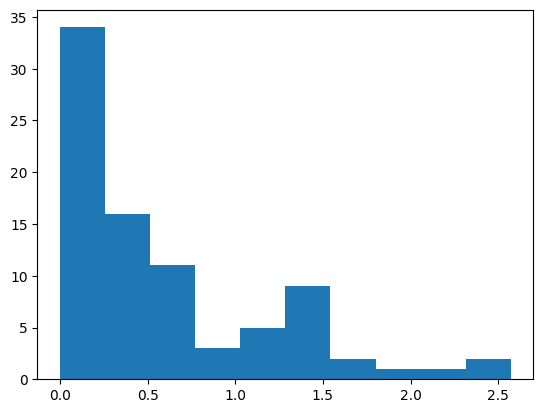

In [21]:
plt.hist(spike_df["Spike Rate"])

In [23]:
spike_df[spike_df.Electrode.isin(seeg_mask)]

,Electrode,X,Y,Z,Spike Rate
1,1TP2-3,-27.70,2.50,-35.35,1.857143
9,2NA5-6,-42.45,-6.65,-24.60,1.371429


In [24]:
spike_df = spike_df[~spike_df.Electrode.isin(seeg_mask)]

In [25]:
spike_df.sort_values(by=['Spike Rate'], ascending=False, inplace=True)

In [27]:
print(len(spike_df))

82


In [28]:
def count_electrode_types(df, col="Electrode"):
    return df[col].str[:3].nunique()

n_types = count_electrode_types(spike_df)
print(n_types)

12


In [29]:
def electrode_type_counts(df, col="Electrode"):
    return df[col].str[:3].value_counts()

print(electrode_type_counts(spike_df))

Electrode
3HC    9
5PI    9
6PF    9
10H    9
11P    9
2NA    8
9NA    7
8CC    7
4GC    5
7PA    5
1TP    4
3HT    1
Name: count, dtype: int64


In [189]:
# finding the electrode with the highest spike activity
# changed rate to peak

max_spike_electrode = spike_df.loc[spike_df['Spike Rate'].idxmax()]

print(f"Electrode with max spike rate: {max_spike_electrode['Electrode']}")
print(max_spike_electrode['Spike Rate'])
print(f"Localization: X={max_spike_electrode['X']}, Y={max_spike_electrode['Y']}, Z={max_spike_electrode['Z']}")

Electrode with max spike rate: 7TB4-5
55.85705194397239
Localization: X=-42.400000000000006, Y=2.1, Z=-35.45


In [190]:
MAX_SPIKE = max_spike_electrode['Spike Rate']

In [191]:
ch_names=list(electrode_coords.keys())
coords_mni_ras = np.array(localization_df[['X_2','Y_2','Z_2']])

montage = mne.channels.make_dig_montage(
    ch_pos=dict(zip(ch_names, coords_mni_ras/1000.0)),
    coord_frame='head'  # because MNI is in MRI space
)

info = mne.create_info(ch_names=ch_names, ch_types='seeg', sfreq=1000)
info.set_montage(montage)

<Info | 8 non-empty values
 bads: []
 ch_names: 1LA1, 1LA2, 1LA3, 1LA4, 1LA5, 1LA6, 2LB1, 2LB2, 2LB3, 2LB4, ...
 chs: 112 sEEG
 custom_ref_applied: False
 dig: 115 items (3 Cardinal, 112 EEG)
 highpass: 0.0 Hz
 lowpass: 500.0 Hz
 meas_date: unspecified
 nchan: 112
 projs: []
 sfreq: 1000.0 Hz
>

In [193]:
identity_trans = mne.transforms.Transform('head', 'mri')  # head → mri
identity_trans['trans'] = np.eye(4)


view_kwargs = dict(azimuth=105, elevation=100, focalpoint=(0, 0, -15))

brain = mne.viz.Brain(
    "fsaverage",
    subjects_dir=subjects_dir,
    cortex="low_contrast",
    alpha=0.25,
    background="white",
    # surf = 'inflated'
)

brain.add_sensors(info, trans=identity_trans)
brain.add_head(alpha=0.25, color="tan")
brain.show_view(distance=400, **view_kwargs)

Channel types::	seeg: 112
Using fsaverage-head-dense.fif for head surface.
    1 BEM surfaces found
    Reading a surface...
[done]
    1 BEM surfaces read


In [194]:
# get standard fsaverage volume (5mm grid) source space
fname_src = subjects_dir / "fsaverage" / "bem" / "fsaverage-vol-5-src.fif"
vol_src = mne.read_source_spaces(fname_src)

aver_src = vol_src

    Reading a source space...
    [done]
    1 source spaces read


In [195]:
import numpy as np
import nibabel as nib
from scipy.spatial import cKDTree

In [196]:
# electrode MNI coordinates (the highest spike rate)
mni_coords_mm = np.array([[15.2, -6.6, -26.6]]) / 1000

# all source points from the source space
all_rr = np.concatenate([s['rr'][s['inuse'].astype(bool)] for s in vol_src])

tree = cKDTree(all_rr)
dist, idx = tree.query(mni_coords_mm) # the index of the closest source point

In [197]:
mne.viz.set_3d_options(antialias=False)

In [198]:
def find_closest(coords, tree):
    mni_coords_mm = np.array([coords]) # coords is a list of x y z
    dist, idx = tree.query(mni_coords_mm) # the index of the closest source point
    return idx

all_rr = np.concatenate([s['rr'][s['inuse'].astype(bool)] for s in vol_src])
tree = cKDTree(all_rr)

In [199]:
coordinates = [[x / 1000, y / 1000, z / 1000] for x, y, z in zip(spike_df.X.values, spike_df.Y.values, spike_df.Z.values)]
spike_rates = spike_df["Spike Rate"].values
src_coords = []
rates = dict()

for electrode, rate in zip(coordinates, spike_rates):
    src_id = find_closest(electrode, tree)
    src_coord = all_rr[src_id]
    if str(src_id) in rates:
        rates[str(src_id)].append(rate)
    else:
        rates[str(src_id)] = [rate]
    src_coords.append(src_coord)  

rates_ = dict([(src_id, sum(rate)/len(rate)) for src_id, rate in rates.items()])

In [200]:
all_rr.shape

(14629, 3)

In [201]:
all_rr_mm = all_rr 
source_coords_mm = all_rr_mm[idx]

In [202]:
source_coords_mm

array([[ 0.015, -0.005, -0.025]])

In [203]:
mni_coords_mm 

array([[ 0.0152, -0.0066, -0.0266]])

In [204]:
n_sources = all_rr.shape[0]
data = np.zeros((n_sources, 100))
for idx in rates.keys():
    idx_ = int(idx.replace('[', '').replace(']', ''))
    data[idx_] = np.array([rates_[idx]] * 100)

vertices = [np.arange(n_sources)]

In [205]:
idxs = [int(x.replace('[', '').replace(']', '')) for x in rates.keys()]

In [206]:
rates_tresh = dict()
rates_tresh_ = dict()
for key, value in rates.items():
    # Threshold check!! fix for IZ
   # rates_tresh[key] = value[0] / MAX_SPIKE
   # rates_tresh_[key] = value[0] / MAX_SPIKE
    if value[0] / MAX_SPIKE > 0.3: #CHANGE
        rates_tresh[key] = value[0] / MAX_SPIKE * 3
        rates_tresh_[key] = value[0] / MAX_SPIKE * 3
    else:
        rates_tresh[key] = [0.0]
        rates_tresh_[key] = 0.0

In [207]:
unique_sorted_indices = np.array(sorted(idxs))
unique_spike_values = [rates_tresh_[f'[{idx}]'] for idx in unique_sorted_indices]
# Создаем данные для VolSourceEstimate
correct_vertices = np.array([vol_src[0]['vertno'][x] for x in sorted(idxs)])
vertices = [correct_vertices]  # Используем уникальные отсортированные индексы
data = np.array(unique_spike_values)[:, np.newaxis]  # Приведение к форме (n_vertices, n_times)

# Проверяем размерность и корректность
print(f"Data shape: {data.shape}, Vertices: {vertices}")

Data shape: (85, 1), Vertices: [array([11063, 11064, 11094, 11127, 12316, 12317, 12347, 12348, 13533,
       13537, 13538, 13540, 13541, 13542, 13605, 13607, 13608, 13609,
       14721, 14722, 14723, 14724, 14725, 14726, 14728, 14729, 14838,
       16160, 16161, 16162, 16196, 16197, 16198, 16199, 16441, 16474,
       16476, 16477, 16478, 17760, 17766, 17768, 17769, 19825, 19826,
       19828, 19829, 19830, 19854, 19856, 19857, 21523, 21524, 21525,
       21526, 21555, 23737, 24827, 24861, 25523, 26111, 26112, 26113,
       26809, 26840, 26841, 27394, 28126, 28724, 28725, 28750, 28751,
       28752, 28753, 28755, 28756, 28780, 28781, 28782, 30533, 30534,
       30535, 30537, 30538, 30539], dtype=int64)]


In [208]:
vals_to_verts = dict(zip(vertices[0].tolist(), unique_spike_values))

all_vertices = vol_src[0]['vertno']
all_values = []
for vert in all_vertices:
    if vert in vals_to_verts.keys():
        all_values.append(vals_to_verts[vert])
    else:
        all_values.append(0)
        
full_data = np.array(all_values)[:, np.newaxis]
full_verts = [all_vertices]

full_stc_seeg = mne.VolSourceEstimate(
    data=full_data,
    vertices=full_verts,
    tmin=0,
    tstep=1,
    subject="fsaverage"
)

In [209]:
full_stc_seeg

<VolSourceEstimate | 14629 vertices, subject : fsaverage, tmin : 0.0 (ms), tmax : 0.0 (ms), tstep : 1000.0 (ms), data shape : (14629, 1), ~229 kB>

In [210]:
iz_seeg = []
for act, vert in zip(data.tolist(), vertices[0].tolist()):
    if act[0] != 0:
        iz_seeg.append(vert)

In [211]:
len(iz_seeg)

19

In [212]:
vol_stc = mne.VolSourceEstimate(
    data=data,
    vertices=vertices,
    tmin=0,
    tstep=1,
    subject="fsaverage"
)

In [213]:
vol_stc

<VolSourceEstimate | 85 vertices, subject : fsaverage, tmin : 0.0 (ms), tmax : 0.0 (ms), tstep : 1000.0 (ms), data shape : (85, 1), ~2 kB>

In [216]:
clim = dict(kind="value", lims=[0.5, 0.7, 0.95])

brain_seeg = vol_stc.plot_3d(
    src=vol_src,
    subjects_dir=subjects_dir,
    view_layout="horizontal",
    views=["axial", "coronal", "sagittal"],
    size=(1600, 600),
    show_traces=0.1,
    background= (1.0, 0.85, 0.75),
    foreground='black',
    clim=clim,
    add_data_kwargs=dict(colorbar_kwargs=dict(label_font_size=1)),
)

brain_seeg.add_foci(
    [[-32.9, -3.75, -27.45]],
    coords_as_verts=False,
    hemi="vol",
    color="blue",
    scale_factor=1.2,
)


In [52]:
aseg_file = fr'{subjects_dir}\fsaverage\mri\aparc+aseg.mgz'
label_names = mne.get_volume_labels_from_aseg(aseg_file)

In [173]:
stc_to_label = mne.extract_label_time_course(
    full_stc_seeg,
    #new_stc,
    (aseg_file, label_names),  
    vol_src,
    mode='max', 
    mri_resolution=True, 
    allow_empty=True 
)

peak_time_idx = np.argmax(np.max(stc_to_label, axis=0))
peak_activations = stc_to_label[:, peak_time_idx]

active_label_indices = np.where(peak_activations > 0)[0]
active_regions = [label_names[i] for i in active_label_indices]

regions_seeg = []
for region in active_regions:
    if ('Unknown' not in region) and ('unknown' not in region) and region != 'Left-Cerebral-White-Matter' and region != 'Right-Cerebral-White-Matter':
        regions_seeg.append(region)

print(len(regions_seeg))
print("Active volume regions:")
for region in regions_seeg:
    print(region)

Reading atlas C:\Users\CCDM\mne_data\MNE-sample-data\subjects\fsaverage\mri\aparc+aseg.mgz
114/114 atlas regions had at least one vertex in the source space
Extracting time courses for 114 labels (mode: max)
7
Active volume regions:
Left-Inf-Lat-Vent
Left-Hippocampus
Left-Amygdala
ctx-lh-entorhinal
ctx-lh-fusiform
ctx-lh-parahippocampal
ctx-lh-temporalpole


In [57]:
from scipy.ndimage import gaussian_filter

def _smooth_binarized_vol_stc(stc: mne.VolSourceEstimate):
    data = stc.data
    if data.shape[1] == 1:  # Single time point
        smoothed_data = gaussian_filter(data.flatten(), sigma=0.7)
    else:  # Multiple time points
        smoothed_data = np.zeros_like(data)
        for t in range(data.shape[1]):
            smoothed_data[:, t] = gaussian_filter(data[:, t], sigma=1)
    
    return smoothed_data.flatten()

In [124]:
full_stc_seeg.data.shape

(14629, 1)

In [125]:
new_stc = mne.VolSourceEstimate(
    data=_smooth_binarized_vol_stc(full_stc_seeg).astype(int),
    vertices=full_verts,
    tmin=0,
    tstep=1,
    subject="fsaverage"
) 

In [133]:
new_stc.plot_3d(
    src=vol_src,
    subjects_dir=subjects_dir,
    view_layout="horizontal",
    views=["axial", "coronal", "sagittal"],
    size=(800, 300),
    show_traces=0.8,
    clim="auto",
    add_data_kwargs=dict(colorbar_kwargs=dict(label_font_size=8)),
)

Using control points [0. 0. 1.]


## MEG IZ

In [217]:
import pickle

# = fr'Z:\Diane_Vrubel\Data\MEG_predictions\{MEG_CASE}_bin_cluster_0.out'

with open(src_meg, 'rb') as f:
    src = pickle.load(f)
    
mne_coords = np.concatenate([s['rr'][s['inuse'].astype(bool)] for s in src])

In [218]:
raw = mne.io.read_raw_fif(raw_file, preload=False)

# 2. Get the index number of the MEG1321 channel

ch_idx = raw.ch_names.index('MEG1321')
sens_coords = raw.info['chs'][ch_idx]['loc'][:3]
    
print(f"Channel: MEG1321")
print(f"X (Left/Right): {sens_coords[0]:.4f} m")
print(f"Y (Anterior/Posterior): {sens_coords[1]:.4f} m")
print(f"Z (Superior/Inferior):  {sens_coords[2]:.4f} m")

Opening raw data file Z:\Diane_Vrubel\Data\MEG\M0K0\MEG_data\tsss_mc_artefact_correction\M0K0_ii_run4_raw_tsss_mc_art_corr.fif...


C:\Users\CCDM\AppData\Local\Temp\ipykernel_5428\3935408308.py:1: RuntimeWarning: This filename (Z:\Diane_Vrubel\Data\MEG\M0K0\MEG_data\tsss_mc_artefact_correction\M0K0_ii_run4_raw_tsss_mc_art_corr.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(raw_file, preload=False)


    Range : 75000 ... 1278999 =     75.000 ...  1278.999 secs
Ready.
Channel: MEG1321
X (Left/Right): 0.1074 m
Y (Anterior/Posterior): 0.0329 m
Z (Superior/Inferior):  0.0081 m


In [219]:
identity_trans = mne.transforms.Transform('head', 'mri')  # head → mri
identity_trans['trans'] = np.eye(4)
mni_coords = mne.head_to_mni(mne_coords, MEG_CASE, trans_meg, subjects_dir=subjects_dir_meg )

activity = np.loadtxt(iz_meg_file)
data = activity[:, np.newaxis]

src_coords = []

for source, rate in zip(mni_coords/1000, activity):
    src_id = find_closest(source, tree)
    src_coord = all_rr[src_id]
    if rate == 1 and src_id.tolist()[0] not in src_coords:
        src_coords.append(src_id.tolist()[0])
correct_vertices = np.array([vol_src[0]['vertno'][x] for x in sorted(src_coords)])
vertices = [correct_vertices]  # Используем уникальные отсортированные индексы

data = np.ones((vertices[0].shape[0],1))
iz_meg = vertices[0].tolist()

all_vertices = vol_src[0]['vertno']
all_values_meg = []
for vert in all_vertices:
    if vert in correct_vertices.tolist():
        all_values_meg.append(3)
    else:
        all_values_meg.append(0)
full_data_meg = np.array(all_values_meg)[:, np.newaxis]
full_verts_meg = [all_vertices]

full_stc_meg = mne.VolSourceEstimate(
    data=full_data_meg,
    vertices=full_verts_meg,
    tmin=0,
    tstep=1,
    subject="fsaverage"
)

iz_stc = mne.VolSourceEstimate(
    data=data,
    vertices=vertices,
    tmin=0,
    tstep=1,
    subject="fsaverage"
)

In [220]:
sens_coords

array([0.1074, 0.0329, 0.0081])

In [221]:
clim = dict(kind="value", lims=[0.5, 0.7, 0.95])

brain_meg = iz_stc.plot_3d(
    src=vol_src,
    subjects_dir=subjects_dir,
    view_layout="horizontal",
    views=["axial", "coronal", "sagittal"],
    size=(1600, 600),
    background = (0.88, 0.95, 0.88),
    foreground = 'black',
    show_traces=False,
    clim=clim,
    add_data_kwargs=dict(colorbar_kwargs=dict(label_font_size=1)),
)
'''
brain_meg.add_foci(
    [sens_coords*100],
    coords_as_verts=False,
    hemi="vol",
    color="green",
    scale_factor=0.8,
)
'''

'\nbrain_meg.add_foci(\n    [sens_coords*100],\n    coords_as_verts=False,\n    hemi="vol",\n    color="green",\n    scale_factor=0.8,\n)\n'

In [82]:
meg_to_label = mne.extract_label_time_course(
    full_stc_meg,
    (aseg_file, label_names),  
    vol_src,
    mode='max', 
    mri_resolution=True, 
    allow_empty=True 
)

peak_time_idx = np.argmax(np.max(meg_to_label, axis=0))
peak_activations = meg_to_label[:, peak_time_idx]

active_label_indices = np.where(peak_activations > 0)[0]
active_regions_meg = [label_names[i] for i in active_label_indices]

regions_meg = []
for region in active_regions_meg:
    if ('Unknown' not in region) and ('unknown' not in region) and region != 'Left-Cerebral-White-Matter' and region != 'Right-Cerebral-White-Matter':
        regions_meg.append(region)

print(len(regions_meg))
print("Active volume regions:")
for region in regions_meg:
    print(region)

Reading atlas C:\Users\CCDM\mne_data\MNE-sample-data\subjects\fsaverage\mri\aparc+aseg.mgz
114/114 atlas regions had at least one vertex in the source space
Extracting time courses for 114 labels (mode: max)
15
Active volume regions:
Left-Inf-Lat-Vent
Brain-Stem
Left-Hippocampus
Left-Amygdala
Right-Hippocampus
Right-Amygdala
ctx-lh-entorhinal
ctx-lh-fusiform
ctx-lh-parahippocampal
ctx-rh-entorhinal
ctx-rh-lateraloccipital
ctx-rh-postcentral
ctx-rh-precentral
ctx-rh-superiortemporal
ctx-rh-supramarginal


## Metrics

In [157]:
interc = []

In [158]:
for region in regions_seeg:
    if region in regions_meg:
        interc.append(region)

for region in regions_meg:
    if region in regions_seeg and region not in interc:
        interc.append(region)

In [160]:
union = set(regions_meg + regions_seeg)

In [164]:
diff = set(regions_meg).difference(interc)